# GraphBG analysis of cancer datasets: GraphBG's domains match with ground truth and it reveals novel/interesting domains
- ENV: biopy311

In [1]:
from numpy.random import default_rng
import scanpy as sc
from anndata import AnnData
import scipy
sc.logging.print_header()
from sklearn.metrics.cluster import adjusted_rand_score
import numpy as np
import pandas as pd
import seaborn as sns
import os
import torch
import pandas as pd
from sklearn import metrics
import multiprocessing as mp
from sklearn.metrics.cluster import normalized_mutual_info_score
import pickle
import os.path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
adata = sc.read_h5ad("/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data/Section_1_GraphBG.h5ad")
true_labels = adata.obs['ground_truth']
pred_labels = adata.obs['GraphBG']
normalized_mutual_info_score(true_labels, pred_labels), homogeneity_score(true_labels, pred_labels), completeness_score(true_labels, pred_labels)

(0.703806177050863, 0.7062617471499433, 0.7013676231142632)

In [4]:
adata = sc.read_h5ad("/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data/Section_1_SpaceFlow.h5ad")
true_labels = adata.obs['ground_truth']
pred_labels = adata.obs['SpaceFlow']
normalized_mutual_info_score(true_labels, pred_labels), homogeneity_score(true_labels, pred_labels), completeness_score(true_labels, pred_labels)

(0.537929705172982, 0.5552864435711179, 0.5216251276223229)

In [5]:
adata = sc.read_h5ad("/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data/Section_1_GraphPCA.h5ad")
true_labels = adata.obs['ground_truth']
pred_labels = adata.obs['GPCA_pred']
# adata.obs['GraphPCA'] = adata.obs['GPCA_pred'].copy()
# adata.write_h5ad(
#     '/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data/Section_1_GraphPCA.h5ad'
# )
normalized_mutual_info_score(true_labels, pred_labels), homogeneity_score(true_labels, pred_labels), completeness_score(true_labels, pred_labels)

(0.6523722682676735, 0.6541786691085554, 0.650575816080038)

In [6]:
adata = sc.read_h5ad("/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data/Section_1_GraphST.h5ad")
true_labels = adata.obs['ground_truth']
pred_labels = adata.obs['GraphST']
normalized_mutual_info_score(true_labels, pred_labels), homogeneity_score(true_labels, pred_labels), completeness_score(true_labels, pred_labels)

(0.6696001645606913, 0.6702507993893909, 0.6689507916928662)

In [7]:
adata = sc.read_h5ad("/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data/Section_1_BASS.h5ad")
true_labels = adata.obs['ground_truth']
pred_labels = adata.obs['BASS']
normalized_mutual_info_score(true_labels, pred_labels), homogeneity_score(true_labels, pred_labels), completeness_score(true_labels, pred_labels)

(0.6696206792851042, 0.6857108788464609, 0.6542682800204117)

GraphBG: (3798, 3000)
SpaceFlow: (3798, 10)
GraphPCA: (3798, 24923)
GraphST: (3798, 36601)

GraphBG columns:
['in_tissue', 'array_row', 'array_col', 'ground_truth', 'domain', 'GraphBG']

SpaceFlow columns:
['in_tissue', 'array_row', 'array_col', 'ground_truth', 'SpaceFlow']

GraphPCA columns:
['in_tissue', 'array_row', 'array_col', 'ground_truth', 'x', 'y', 'GPCA_pred', 'GraphPCA']

GraphST columns:
['in_tissue', 'array_row', 'array_col', 'ground_truth', 'mclust', 'domain', 'GraphST']


/tmp/ipykernel_46555/425545075.py:143: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name, max(len(labels), 1))
/tmp/ipykernel_46555/425545075.py:143: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name, max(len(labels), 1))
/tmp/ipykernel_46555/425545075.py:143: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name, max(len(labels), 1))
/tmp/ipykernel_46555/425545075.py:143: MatplotlibDeprecati

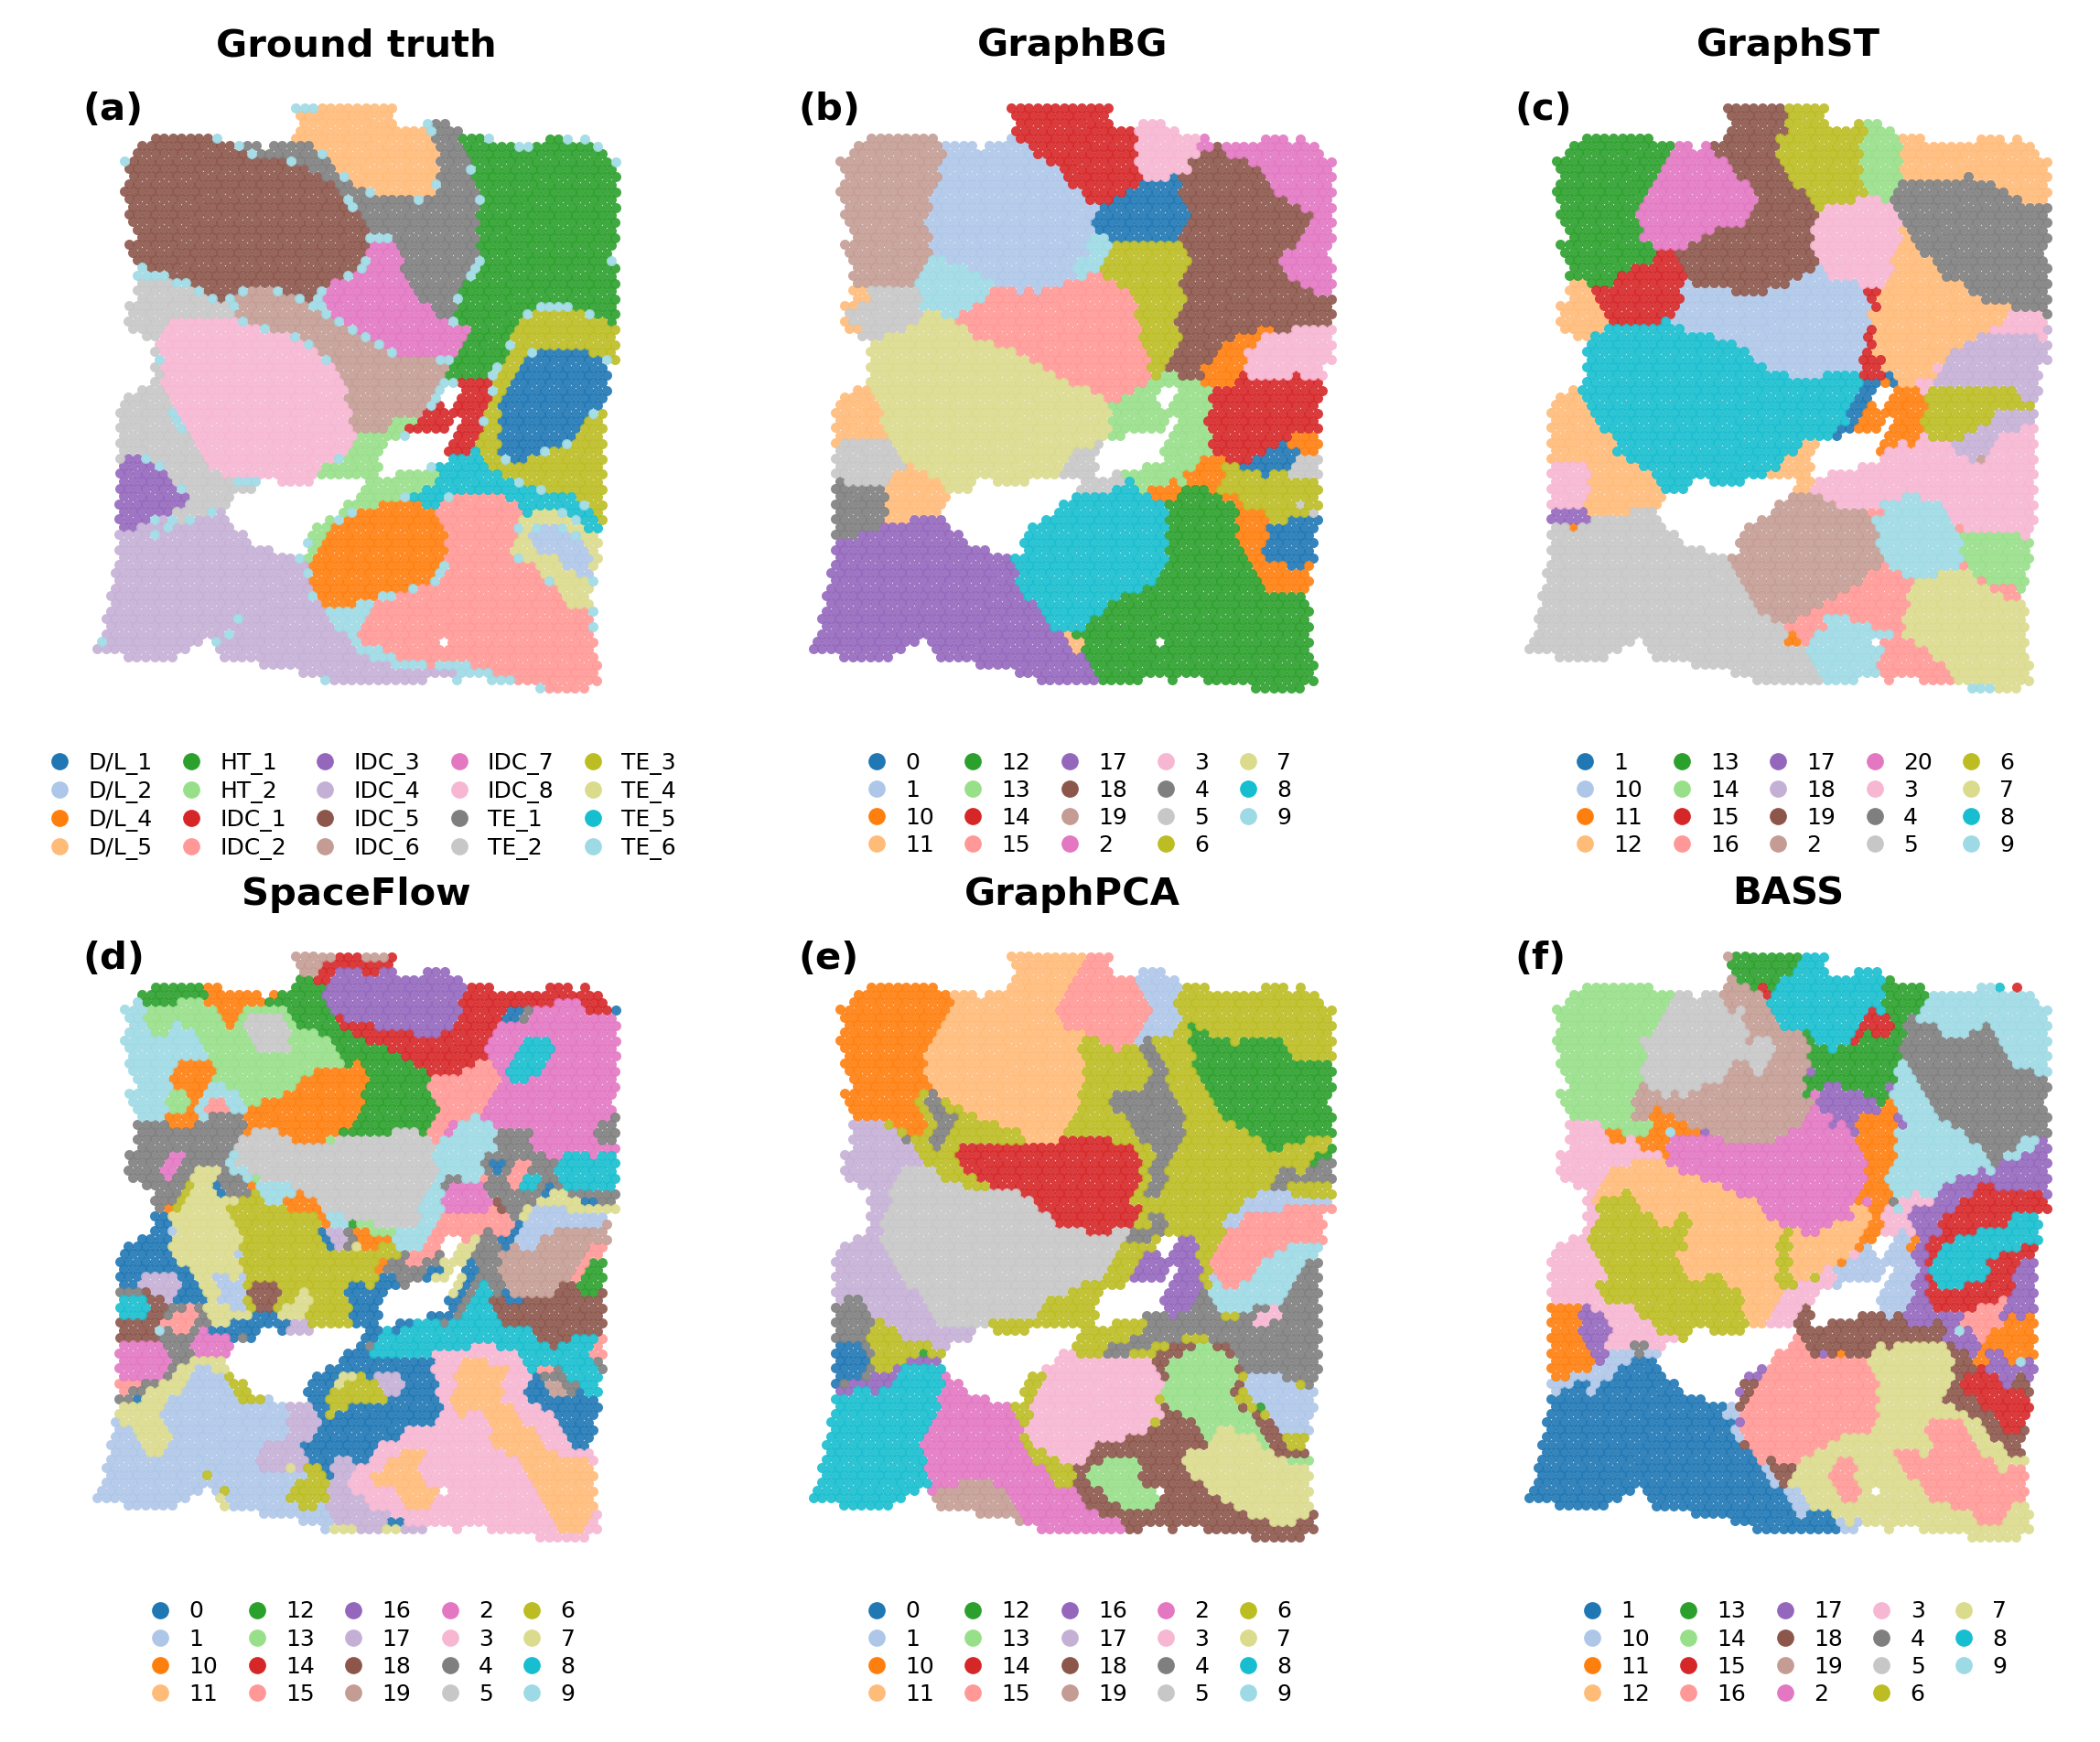

In [8]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.cm as cm


# ============================================================
# 1. Load data
# ============================================================

data_dir = "/data/hoan/spatial_transcriptomics/GraphBG-analysis/Data"

adata_graphbg = sc.read_h5ad(
    f"{data_dir}/Section_1_GraphBG.h5ad"
)

adata_graphbg.obs["ground_truth"] = (
    adata_graphbg.obs["ground_truth"]
    .astype(str)
    .str.replace(r"^Healthy_(\d+)$", r"HT_\1", regex=True)
    .str.replace(r"^Tumor_edge_(\d+)$", r"TE_\1", regex=True)
    .str.replace(r"^DCIS/LCIS_(\d+)$", r"D/L_\1", regex=True)
)

adata_spaceflow = sc.read_h5ad(
    f"{data_dir}/Section_1_SpaceFlow.h5ad"
)

adata_graphpca = sc.read_h5ad(
    f"{data_dir}/Section_1_GraphPCA.h5ad"
)

adata_graphst = sc.read_h5ad(
    f"{data_dir}/Section_1_GraphST.h5ad"
)

adata_bass = sc.read_h5ad(
    f"{data_dir}/Section_1_BASS.h5ad"
)


# ============================================================
# 2. Check that all datasets contain the required information
# ============================================================

print("GraphBG:", adata_graphbg.shape)
print("SpaceFlow:", adata_spaceflow.shape)
print("GraphPCA:", adata_graphpca.shape)
print("GraphST:", adata_graphst.shape)

required_columns = {
    "GraphBG": adata_graphbg.obs.columns,
    "SpaceFlow": adata_spaceflow.obs.columns,
    "GraphPCA": adata_graphpca.obs.columns,
    "GraphST": adata_graphst.obs.columns,
}

for method, columns in required_columns.items():
    print(f"\n{method} columns:")
    print(list(columns))


# ============================================================
# 3. Define the annotation used for each method
# ============================================================

annotations = {
    "Ground truth": (
        adata_graphbg,
        "ground_truth"
    ),

    "GraphBG": (
        adata_graphbg,
        "GraphBG"
    ),

    "GraphST": (
        adata_graphst,
        "GraphST"
    ),

    "SpaceFlow": (
        adata_spaceflow,
        "SpaceFlow"
    ),

    "GraphPCA": (
        adata_graphpca,
        "GraphPCA"
    ),
  "BASS": (
        adata_bass,
        "BASS"
    ),
}


# ============================================================
# 4. Make sure spatial coordinates are available
# ============================================================

for name, (adata, annotation) in annotations.items():

    if "spatial" not in adata.obsm:

        raise ValueError(
            f"{name}: adata.obsm['spatial'] is missing."
        )

    if annotation not in adata.obs:

        raise ValueError(
            f"{name}: annotation '{annotation}' "
            f"is missing from adata.obs."
        )


# ============================================================
# 5. Create independent colors for each panel
#
# Important:
# Cluster IDs are method-specific.
#
# GraphBG cluster 1 does NOT necessarily correspond to
# GraphST cluster 1.
#
# Therefore each method gets its own color assignment.
# ============================================================

def create_color_map(labels, cmap_name="tab20"):

    labels = sorted(
        [str(x) for x in pd.unique(labels)],
        key=lambda x: (
            not x.replace(".", "", 1).isdigit(),
            x
        )
    )

    cmap = cm.get_cmap(cmap_name, max(len(labels), 1))

    color_map = {
        label: cmap(i)
        for i, label in enumerate(labels)
    }

    return color_map


color_maps = {}

for name, (adata, annotation) in annotations.items():

    labels = adata.obs[annotation].astype(str)

    color_maps[name] = create_color_map(
        labels,
        cmap_name="tab20"
    )


# ============================================================
# 6. Plotting function
# ============================================================

def plot_spatial_panel(
    ax,
    adata,
    annotation,
    color_map,
    title,
    point_size=7,
    alpha=0.90
):

    xy = np.asarray(
        adata.obsm["spatial"]
    )

    labels = (
        adata.obs[annotation]
        .astype(str)
        .values
    )

    unique_labels = sorted(
        np.unique(labels)
    )

    # --------------------------------------------------------
    # Plot each cluster separately
    # --------------------------------------------------------

    for label in unique_labels:

        mask = labels == label

        ax.scatter(
            xy[mask, 0],
            xy[mask, 1],
            s=point_size,
            color=color_map[label],
            linewidths=0,
            alpha=alpha,
            rasterized=True,
        )

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=10,
        fontweight="bold",
        pad=6
    )

    ax.set_aspect("equal")

    # Spatial transcriptomics image convention
    ax.invert_yaxis()

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xlabel("")
    ax.set_ylabel("")

    # Remove box
    for spine in ax.spines.values():
        spine.set_visible(False)

    return unique_labels


# ============================================================
# 7. Nature-style matplotlib settings
# ============================================================

plt.rcParams.update({

    "font.family": "DejaVu Sans",

    "font.size": 8,

    "axes.linewidth": 0.8,

    "xtick.major.width": 0.8,

    "ytick.major.width": 0.8,

    "xtick.major.size": 3,

    "ytick.major.size": 3,

})


# ============================================================
# 8. Create 2 × 3 figure
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(8.2, 6.3),
    dpi=300
)

axes = axes.flatten()


# ============================================================
# 9. Panel definitions
# ============================================================

panel_info = [

    (
        "a",
        "Ground truth",
        adata_graphbg,
        "ground_truth",
    ),

    (
        "b",
        "GraphBG",
        adata_graphbg,
        "GraphBG",
    ),

    (
        "c",
        "GraphST",
        adata_graphst,
        "GraphST",
    ),

    (
        "d",
        "SpaceFlow",
        adata_spaceflow,
        "SpaceFlow",
    ),

    (
        "e",
        "GraphPCA",
        adata_graphpca,
        "GraphPCA",
    ),

    (
        "f",
        "BASS",
        adata_bass,
        "BASS",
    ),

]


# ============================================================
# 10. Plot panels
# ============================================================

panel_labels = {}

for i, (
    letter,
    title,
    adata,
    annotation,
) in enumerate(panel_info):

    color_map = color_maps[title]

    labels = plot_spatial_panel(
        ax=axes[i],
        adata=adata,
        annotation=annotation,
        color_map=color_map,
        title=title,
        point_size=7,
        alpha=0.90,
    )

    panel_labels[title] = labels

    # --------------------------------------------------------
    # Panel letter
    # --------------------------------------------------------

    axes[i].text(
        0.02,
        0.98,
        f"({letter})",
        transform=axes[i].transAxes,
        ha="left",
        va="top",
        fontsize=10,
        fontweight="bold",
    )


# ============================================================
# 11. Sixth panel
#
# Reserved for zoom / additional analysis
# ============================================================

# axes[5].axis("off")

# axes[5].text(
#     0.5,
#     0.5,
#     "Zoomed region",
#     transform=axes[5].transAxes,
#     ha="center",
#     va="center",
#     fontsize=9,
#     color="gray",
# )


# ============================================================
# 12. Create legends
#
# Each method has its OWN cluster labels.
# ============================================================

# We create compact legends and place them below each
# corresponding panel.
#
# This is preferable to one global legend because:
#
# GraphBG cluster 1 != GraphST cluster 1
# ============================================================

for i, (
    letter,
    title,
    adata,
    annotation,
) in enumerate(panel_info):

    ax = axes[i]

    labels = panel_labels[title]

    color_map = color_maps[title]

    handles = [

        Line2D(
            [0],
            [0],

            marker="o",

            linestyle="",

            markerfacecolor=color_map[label],

            markeredgecolor="none",

            markersize=4.5,

            label=label,
        )

        for label in labels
    ]

    # --------------------------------------------------------
    # Put legend below each spatial map
    # --------------------------------------------------------

    ax.legend(
        handles=handles,

        loc="upper center",

        bbox_to_anchor=(
            0.5,
            -0.04
        ),

        ncol=min(5, len(handles)),

        frameon=False,

        fontsize=6,

        handletextpad=0.25,

        columnspacing=0.7,

        labelspacing=0.25,

        borderaxespad=0,
    )


# ============================================================
# 13. Layout
# ============================================================

plt.subplots_adjust(

    left=0.04,

    right=0.96,

    bottom=0.08,

    top=0.94,

    wspace=0.12,

    hspace=0.33,
)


# ============================================================
# 14. Overall title
# ============================================================

# fig.suptitle(
#     "Spatial domain detection",
#     fontsize=12,
#     fontweight="bold",
#     y=0.985,
# )


# ============================================================
# 15. Save
# ============================================================

plt.savefig(
    "Section_1_spatial_domain_comparison.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.savefig(
    "Section_1_spatial_domain_comparison.png",
    bbox_inches="tight",
    dpi=600,
)

plt.show()